In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
con = duckdb.connect("tracking_analysis.duckdb")

# 1. All systems
con.execute("""
CREATE OR REPLACE TABLE UID_STATS AS
SELECT uid, MAX(duration) / 60.0 AS duration_hr
FROM read_parquet('track_amazon_lluc/tracking_table/monthly/*.parquet')
WHERE uid IS NOT NULL
  AND duration IS NOT NULL
  AND isfinite(duration)
GROUP BY uid
""")

# 2. Systems with duration >= 60 minutes
con.execute("""
CREATE OR REPLACE TABLE UID_STATS_60 AS
SELECT uid, MAX(duration) / 60.0 AS duration_hr
FROM read_parquet('tracking_table_60min.parquet')
WHERE uid IS NOT NULL
  AND duration IS NOT NULL
  AND isfinite(duration)
GROUP BY uid
""")

# 3. Systems with duration >= 120 minutes
con.execute("""
CREATE OR REPLACE TABLE UID_STATS_120 AS
SELECT uid, MAX(duration) / 60.0 AS duration_hr
FROM read_parquet('tracking_table_120min.parquet')
WHERE uid IS NOT NULL
  AND duration IS NOT NULL
  AND isfinite(duration)
GROUP BY uid
""")

In [4]:
# Load the three tables from DuckDB into pandas DataFrames
df_all = con.execute("SELECT * FROM UID_STATS").df()
df_60min = con.execute("SELECT * FROM UID_STATS_60").df()
df_120min = con.execute("SELECT * FROM UID_STATS_120").df()

table_names = {
    "All systems": "UID_STATS",
    "Duration >= 60 min": "UID_STATS_60",
    "Duration >= 120 min": "UID_STATS_120"
}

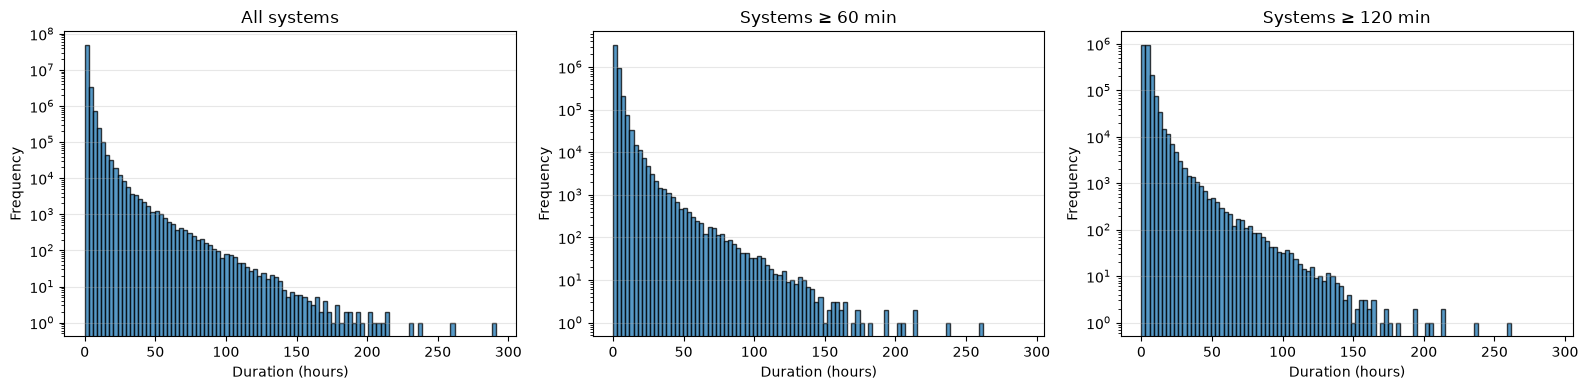

In [5]:
# DataFrames
datasets = {
    "All systems": df_all["duration_hr"].dropna(),
    "Systems ≥ 60 min": df_60min["duration_hr"].dropna(),
    "Systems ≥ 120 min": df_120min["duration_hr"].dropna()
}

# Use the same bin edges for all three distributions
n_bins = 100

min_val = min(data.min() for data in datasets.values())
max_val = max(data.max() for data in datasets.values())

bins = np.linspace(min_val, max_val, n_bins + 1)
bin_width = bins[1] - bins[0]

# Create three panels
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, (title, data) in zip(axes, datasets.items()):
    frequency, bin_edges = np.histogram(data, bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(centers, frequency, width=bin_width, edgecolor="black", alpha=0.75)
    ax.set_xlabel("Duration (hours)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
for name, df in {"All systems": df_all, "At least 60 min": df_60min, "At least 120 min": df_120min}.items():
    print(f"\n{name}")
    print(f"Number of systems: {len(df):,}")
    print(f"Minimum duration: {df['duration_hr'].min():.2f} h")
    print(f"Maximum duration: {df['duration_hr'].max():.2f} h")

for name, data in datasets.items():
    frequency, _ = np.histogram(data, bins=bins)
    print(f"{name}: "f"maximum frequency = {frequency.max():,}, "f"total systems = {frequency.sum():,}")

for name, df in {"All systems": df_all, "At least 60 min": df_60min, "At least 120 min": df_120min}.items():
    print(f"\n{name}")
    print(df["duration_hr"].value_counts().head(5).sort_index())


All systems
Number of systems: 53,103,422
Minimum duration: 0.00 h
Maximum duration: 291.00 h

At least 60 min
Number of systems: 4,543,318
Minimum duration: 1.00 h
Maximum duration: 260.50 h

At least 120 min
Number of systems: 2,242,025
Minimum duration: 2.00 h
Maximum duration: 260.50 h
All systems: maximum frequency = 48,457,442, total systems = 53,103,422
Systems ≥ 60 min: maximum frequency = 3,231,651, total systems = 4,543,318
Systems ≥ 120 min: maximum frequency = 940,281, total systems = 2,242,025

All systems
duration_hr
0.0    27935381
0.5     8677245
1.0     5345831
1.5     3020848
2.0     2039147
Name: count, dtype: int64

At least 60 min
duration_hr
1.0    1478040
1.5     823253
2.0     547898
2.5     382460
3.0     281470
Name: count, dtype: int64

At least 120 min
duration_hr
2.0    547898
2.5    382460
3.0    281470
3.5    212607
4.0    160424
Name: count, dtype: int64
